# 14 - Perbandingan Model Supervised Learning

Notebook ini menggabungkan hasil dari `08_SVM.ipynb` sampai `13_XGBoost.ipynb`, seperti cara `07_Perbandingan.ipynb` menggabungkan hasil K-Means dan DBSCAN.

**Cara membaca hasil:**
- **Klasifikasi:** Macro-F1 dan Balanced accuracy lebih informatif saat distribusi kelas tidak seimbang; Accuracy ditampilkan sebagai metrik tambahan.
- **Regresi:** MAE dan RMSE lebih kecil biasanya lebih baik; R² yang negatif berarti model lebih buruk daripada baseline rata-rata pada data uji.
- **Baseline** adalah pembanding sederhana: kelas berdasarkan `lag_1`, jumlah penjualan berdasarkan `lag_7`.

Model hanya bisa dibandingkan secara adil jika setiap notebook memakai dataset, split waktu, `SEED`, dan `MAX_EVAL_ROWS` yang sama.

## 0. Import & muat hasil semua model

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FOLDER = 'Clustering_Stok'
kandidat_folder = [FOLDER, os.path.join('Quiz', FOLDER), os.path.join('/content/Quiz', FOLDER)]
folder_hasil = next((p for p in kandidat_folder if os.path.isdir(p) and glob.glob(os.path.join(p, 'eval_ml_*.csv'))), None)

files_eval = sorted(glob.glob(os.path.join(folder_hasil, 'eval_ml_*.csv')))
eval_all = pd.concat([pd.read_csv(p) for p in files_eval], ignore_index=True)
# Setiap notebook memuat baseline identik; simpan satu saja.
eval_all = eval_all.drop_duplicates(subset=['Model'], keep='first').reset_index(drop=True)
print('Folder hasil          :', folder_hasil)
print('File hasil ditemukan  :', len(files_eval))
print('Model/baris unik      :', len(eval_all))
display(eval_all.head())

Folder hasil          : Clustering_Stok
File hasil ditemukan  : 6
Model/baris unik      : 7


,Model,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,MAE,RMSE,R2,Waktu (s)
0,Bayes,0.396000,0.392513,0.380412,0.403510,0.732508,0.899479,0.060967,0.744192
1,"Baseline (kelas lag-1, regresi lag-7)",0.428667,0.390229,0.390001,0.427217,0.892667,1.254060,-0.825306,0.000000
2,CatBoost,0.443333,0.455474,0.431058,0.452117,0.721505,0.894363,0.071618,34.388861
3,KNN,0.426000,0.379609,0.380467,0.422553,0.769634,0.963896,-0.078348,4.704687
4,LightGBM,0.426000,0.438109,0.411122,0.434224,0.721855,0.896540,0.067094,2.526114


## 1. Tabel perbandingan klasifikasi

,Model,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,Waktu (s)
0,CatBoost,0.4433,0.4555,0.4311,0.4521,34.3889
1,SVM,0.4553,0.4465,0.4148,0.4454,1.6608
2,LightGBM,0.4260,0.4381,0.4111,0.4342,2.5261
3,"Baseline (kelas lag-1, regresi lag-7)",0.4287,0.3902,0.3900,0.4272,0.0000
4,KNN,0.4260,0.3796,0.3805,0.4226,4.7047
5,Bayes,0.3960,0.3925,0.3804,0.4035,0.7442
6,XGBoost,0.4740,0.3845,0.3750,0.4397,3.8185


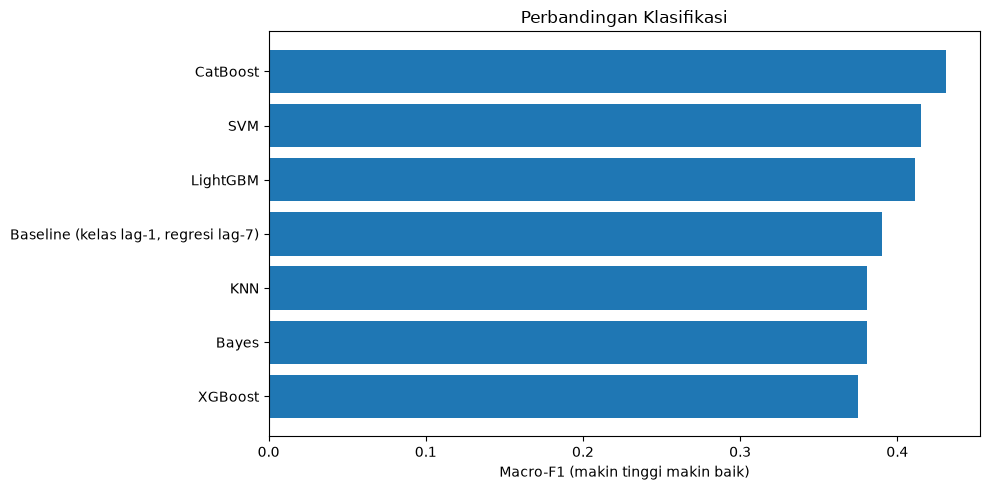

In [2]:
kolom_cls = ['Model', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'Weighted-F1', 'Waktu (s)']
tabel_cls = eval_all.dropna(subset=['Macro-F1'])[kolom_cls].sort_values('Macro-F1', ascending=False).reset_index(drop=True)
display(tabel_cls.round(4))

plt.figure(figsize=(10, 5))
plt.barh(tabel_cls.sort_values('Macro-F1')['Model'], tabel_cls.sort_values('Macro-F1')['Macro-F1'])
plt.xlabel('Macro-F1 (makin tinggi makin baik)')
plt.title('Perbandingan Klasifikasi')
plt.tight_layout()
plt.show()

## 2. Tabel perbandingan regresi

,Model,MAE,RMSE,R2,Waktu (s)
0,SVM,0.6400,0.9324,-0.0090,1.6608
1,CatBoost,0.7215,0.8944,0.0716,34.3889
2,LightGBM,0.7219,0.8965,0.0671,2.5261
3,XGBoost,0.7222,0.8989,0.0623,3.8185
4,Bayes,0.7325,0.8995,0.0610,0.7442
5,KNN,0.7696,0.9639,-0.0783,4.7047
6,"Baseline (kelas lag-1, regresi lag-7)",0.8927,1.2541,-0.8253,0.0000


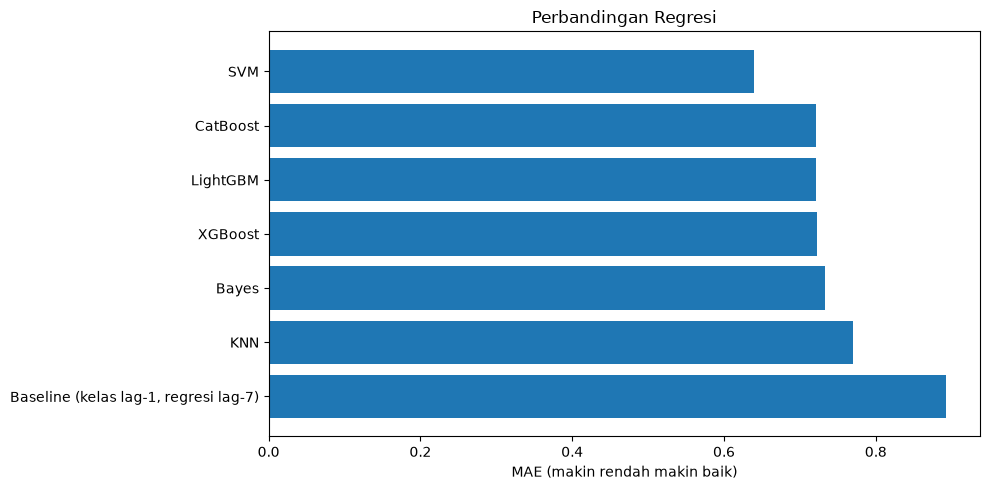

In [3]:
kolom_reg = ['Model', 'MAE', 'RMSE', 'R2', 'Waktu (s)']
tabel_reg = eval_all.dropna(subset=['MAE'])[kolom_reg].sort_values('MAE', ascending=True).reset_index(drop=True)
display(tabel_reg.round(4))

plt.figure(figsize=(10, 5))
plot_reg = tabel_reg.sort_values('MAE', ascending=False)
plt.barh(plot_reg['Model'], plot_reg['MAE'])
plt.xlabel('MAE (makin rendah makin baik)')
plt.title('Perbandingan Regresi')
plt.tight_layout()
plt.show()

## 3. Simpan tabel perbandingan

In [4]:
path_cls = os.path.join(folder_hasil, 'perbandingan_ml_klasifikasi.csv')
path_reg = os.path.join(folder_hasil, 'perbandingan_ml_regresi.csv')
tabel_cls.to_csv(path_cls, index=False)
tabel_reg.to_csv(path_reg, index=False)
print('Tabel klasifikasi tersimpan:', path_cls)
print('Tabel regresi tersimpan    :', path_reg)
if len(tabel_cls):
    model_cls = tabel_cls[~tabel_cls['Model'].str.startswith('Baseline')]
    if len(model_cls): print('Macro-F1 tertinggi:', model_cls.iloc[0]['Model'], f"({model_cls.iloc[0]['Macro-F1']:.4f})")
if len(tabel_reg):
    model_reg = tabel_reg[~tabel_reg['Model'].str.startswith('Baseline')]
    if len(model_reg): print('MAE terendah      :', model_reg.iloc[0]['Model'], f"({model_reg.iloc[0]['MAE']:.4f})")

Tabel klasifikasi tersimpan: Clustering_Stok\perbandingan_ml_klasifikasi.csv
Tabel regresi tersimpan    : Clustering_Stok\perbandingan_ml_regresi.csv
Macro-F1 tertinggi: CatBoost (0.4311)
MAE terendah      : SVM (0.6400)


## 4. Catatan metodologis

1. Label klasifikasi adalah label eksperimen turunan dari `qty`, bukan label kategori asli pada data.
2. Split berbasis tanggal mengurangi risiko pelatihan memakai tanggal yang lebih baru daripada tanggal uji.
3. Fitur lag test menggunakan data aktual hari sebelumnya. Ini mengevaluasi skenario prediksi satu hari ke depan secara bergulir, bukan memprediksi seluruh masa depan tanpa pembaruan data.
4. Baseline yang sederhana perlu tetap dipertimbangkan. Model yang kompleks tidak otomatis lebih baik.